In [2]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

## Imports

In [2]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models
import torch.nn as nn

The classes names in the dataset are $\\[20pt]$
{'r-pass', 'r_spike', 'r_set', 'l-spike', 'r_winpoint', 'l-pass', 'l_set', 'l_winpoint'}




In [3]:
train_numbers = "1 3 6 7 10 13 15 16 18 22 23 31 32 36 38 39 40 41 42 48 50 52 53 54".split()
val_numbers = "0 2 8 12 17 19 24 26 27 28 30 33 46 49 51".split()
test_numbers = "4 5 9 11 14 20 21 25 29 34 35 37 43 44 45 47".split()
group_classes = ['l-pass', 'r-pass', 'l_set', 'r_set' ,'l-spike', 'r_spike', 'l_winpoint', 'r_winpoint']
class2id = {classification:idx for idx,classification in enumerate(group_classes)}

## Vizualizing Sample of image level classification images

In [4]:
os.listdir(f'/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/{train_numbers[0]}')

['14440',
 '40425',
 '12685',
 '24945',
 '21585',
 '33195',
 '42920',
 '24995',
 '9865',
 '40160',
 '40655',
 '25090',
 '39345',
 '39130',
 '13100',
 '12720',
 '42885',
 '43685',
 '12870',
 '24900',
 '10940',
 '31710',
 '13035',
 '31605',
 '12780',
 '47410',
 '45555',
 '31465',
 '39310',
 '40120',
 '43610',
 '14630',
 '45675',
 '31535',
 '52470',
 '31720',
 '46470',
 '24865',
 '9805',
 '45595',
 '31645',
 '47435',
 '28775',
 '40190',
 '40380',
 '10685',
 '28860',
 '40230',
 '28580',
 '24825',
 '43825',
 '43890',
 '42990',
 '21695',
 '13110',
 '10825',
 '10915',
 '12880',
 '25120',
 '9760',
 '10750',
 '21500',
 '36345',
 '9905',
 '9995',
 '9685',
 '21530',
 '9825',
 '40605',
 '14490',
 '40255',
 '28790',
 '43760',
 '14585',
 '25150',
 '40350',
 '10780',
 '38505',
 '24885',
 '21685',
 '25160',
 '28545',
 '43640',
 '42955',
 '40045',
 '40490',
 'annotations.txt',
 '31435',
 '47380',
 '40455',
 '39200',
 '10645',
 '31565',
 '33900',
 '28810',
 '42865',
 '40275',
 '9715',
 '10890',
 '32460'

In [5]:
with open(f'/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/{train_numbers[0]}/annotations.txt','r') as file:
    # content = file.read()
    target_frames = [(line.split()[:2]) for line in file if line.split()]
# print(content)
print(target_frames)

[['9575.jpg', 'r_spike'], ['39310.jpg', 'r_set'], ['10645.jpg', 'r-pass'], ['9685.jpg', 'l-spike'], ['39065.jpg', 'l-pass'], ['47435.jpg', 'l-spike'], ['39140.jpg', 'r-pass'], ['31395.jpg', 'r-pass'], ['24945.jpg', 'l_set'], ['24995.jpg', 'l-pass'], ['13110.jpg', 'l-spike'], ['21500.jpg', 'l_set'], ['9760.jpg', 'r-pass'], ['42885.jpg', 'l-pass'], ['21530.jpg', 'r-pass'], ['28775.jpg', 'r_spike'], ['28860.jpg', 'l-spike'], ['40190.jpg', 'r_set'], ['24865.jpg', 'l-spike'], ['10940.jpg', 'r_spike'], ['9825.jpg', 'l-pass'], ['40370.jpg', 'r-pass'], ['12780.jpg', 'r_spike'], ['28790.jpg', 'l-pass'], ['40160.jpg', 'l-spike'], ['40380.jpg', 'r-pass'], ['28810.jpg', 'l-pass'], ['9715.jpg', 'r-pass'], ['40045.jpg', 'r_spike'], ['10580.jpg', 'l_set'], ['39265.jpg', 'r_set'], ['28635.jpg', 'l-pass'], ['10720.jpg', 'r_spike'], ['12725.jpg', 'r_set'], ['39100.jpg', 'l_set'], ['21685.jpg', 'l-spike'], ['31435.jpg', 'r_set'], ['28570.jpg', 'r_spike'], ['31565.jpg', 'l-spike'], ['40525.jpg', 'r_set'],

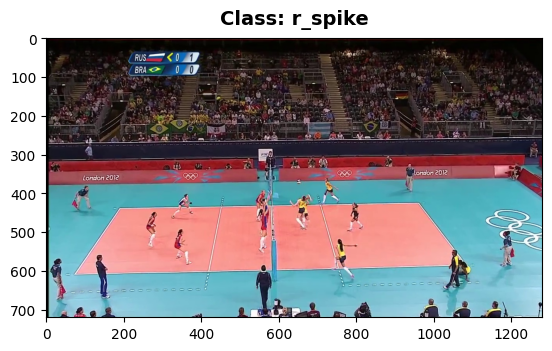

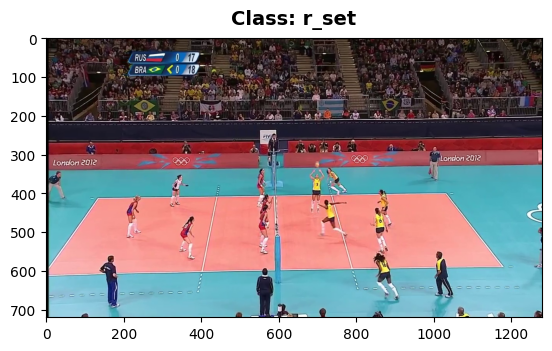

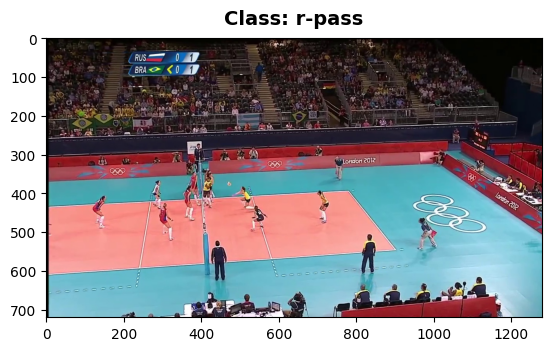

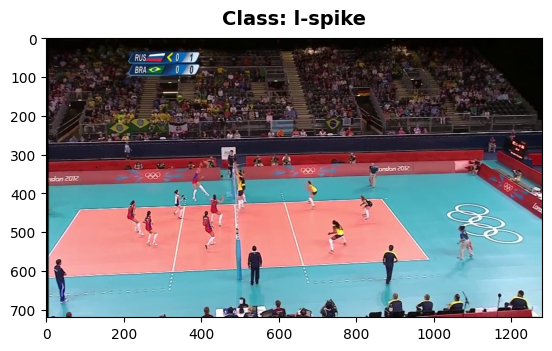

In [6]:
for frame in target_frames[:4]:
    frame_name = frame[0][:-4]
    img = Image.open(f'/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos/{train_numbers[0]}/{frame_name}/{frame[0]}')
    plt.imshow(img)
    plt.title(f"Class: {frame[1]}", fontsize=14, fontweight='bold', pad=10)
    plt.show()
    
    # break

## Creating Image Level Classification Dataset

In [7]:
class ImageLevelDataset(Dataset):

    def __init__(self,split_ids,mapper,transform = None):

        self.base_dir = "/kaggle/input/datasets/sherif31/group-activity-recognition-volleyball/videos"
        self.samples = []
        self.mapper = mapper
        self.transform = transform

        for split_id in split_ids:
            
            annotations_path = os.path.join(self.base_dir,str(split_id),'annotations.txt')
            
            with open(annotations_path,'r') as file:
                for line in file:
                    parts = line.strip().split()
                    if len(parts) < 2:
                        continue
                    frame_name = parts[0]
                    frame_class = parts[1]
                    frame_folder = frame_name.split(".")[0]
                    frame_path = os.path.join(self.base_dir,str(split_id),frame_folder,frame_name)
                    self.samples.append((frame_path,self.mapper[frame_class]))

    def __len__(self):
        return len(self.samples)


    def __getitem__(self,idx):
        img_path = self.samples[idx][0]
        img_class = self.samples[idx][1]

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)
        return image, img_class
        
                

            
        

In [8]:
BATCH_SIZE = 32
NUM_WORKERS = 4

In [9]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop((224, 224)),
    # Removed RandomHorizontalFlip because labels are directional (left/right)
    transforms.ColorJitter(brightness=0.2, contrast=0.2), # Safe alternative augmentation
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [10]:
train_dataset = ImageLevelDataset(train_numbers,class2id,train_transform)
val_dataset = ImageLevelDataset(val_numbers,class2id,val_transform)

In [11]:
train_loader = DataLoader(train_dataset,batch_size = BATCH_SIZE, shuffle = True, num_workers = NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size = BATCH_SIZE, shuffle = False, num_workers = NUM_WORKERS)

In [12]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
num_classes = len(class2id)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)
criterion = nn.CrossEntropyLoss()
# 1. Freeze all parameters first
for param in model.parameters():
    param.requires_grad = False

# 2. Unfreeze layer4 for higher-level domain adaptation
for param in model.layer4.parameters():
    param.requires_grad = True

# 3. Unfreeze the final classification head
for param in model.fc.parameters():
    param.requires_grad = True

# Pass ONLY trainable parameters to the optimizer (saves memory & computation)
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()), 
    lr=1e-4, 
    weight_decay=1e-4
)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 213MB/s] 


In [13]:
print(device)

cuda


In [14]:
import torch
from tqdm.auto import tqdm

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    # Wrap dataloader with tqdm
    pbar = tqdm(dataloader, desc="Training", leave=False)
    
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels)
        total += labels.size(0)
        
        # Live updates on progress bar
        current_loss = running_loss / total
        current_acc = (correct.double() / total).item() * 100
        pbar.set_postfix(loss=f"{current_loss:.4f}", acc=f"{current_acc:.2f}%")
        
    epoch_loss = running_loss / total
    epoch_acc = (correct.double() / total).item() * 100
    return epoch_loss, epoch_acc


def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    # Wrap dataloader with tqdm
    pbar = tqdm(dataloader, desc="Validation", leave=False)
    
    with torch.no_grad():
        for images, labels in pbar:
            images, labels = images.to(device), labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == labels)
            total += labels.size(0)
            
            # Live updates on progress bar
            current_loss = running_loss / total
            current_acc = (correct.double() / total).item() * 100
            pbar.set_postfix(loss=f"{current_loss:.4f}", acc=f"{current_acc:.2f}%")
            
    val_loss = running_loss / total
    val_acc = (correct.double() / total).item() * 100
    return val_loss, val_acc


# --- Main Training Pipeline ---
num_epochs = 15
best_acc = 0.0

# Overall Progress Bar across Epochs
for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    
    print(f"Summary -> Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")
    
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), 'best_b1_resnet50.pth')
        print(f"--> Saved Best Model with Acc: {best_acc:.2f}%")


Epoch 1/15


Training:   0%|          | 0/68 [00:00<?, ?it/s]

Validation:   0%|          | 0/42 [00:00<?, ?it/s]

Summary -> Train Loss: 2.0167 | Train Acc: 18.87% | Val Loss: 1.9879 | Val Acc: 22.60%
--> Saved Best Model with Acc: 22.60%

Epoch 2/15


Training:   0%|          | 0/68 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/42 [00:00<?, ?it/s]

Summary -> Train Loss: 0.3417 | Train Acc: 88.10% | Val Loss: 1.2692 | Val Acc: 62.49%

Epoch 15/15


Training:   0%|          | 0/68 [00:00<?, ?it/s]

Validation:   0%|          | 0/42 [00:00<?, ?it/s]

Summary -> Train Loss: 0.2840 | Train Acc: 90.33% | Val Loss: 1.2068 | Val Acc: 62.27%
